<a href="https://colab.research.google.com/github/bforoura/ML26/blob/main/Module7_Dimensionality/plant_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Dimensionality Reduction and Principal Component Analysis (PCA)**

* This notebook demonstrates core concepts in unsupervised dimensionality reduction using a real-world image dataset.

* We will explore why high-dimensional spaces pose computational and statistical challenges, how linear projection methods extract dominant patterns, and how to balance information preservation with data compression.


## **Key Topics**

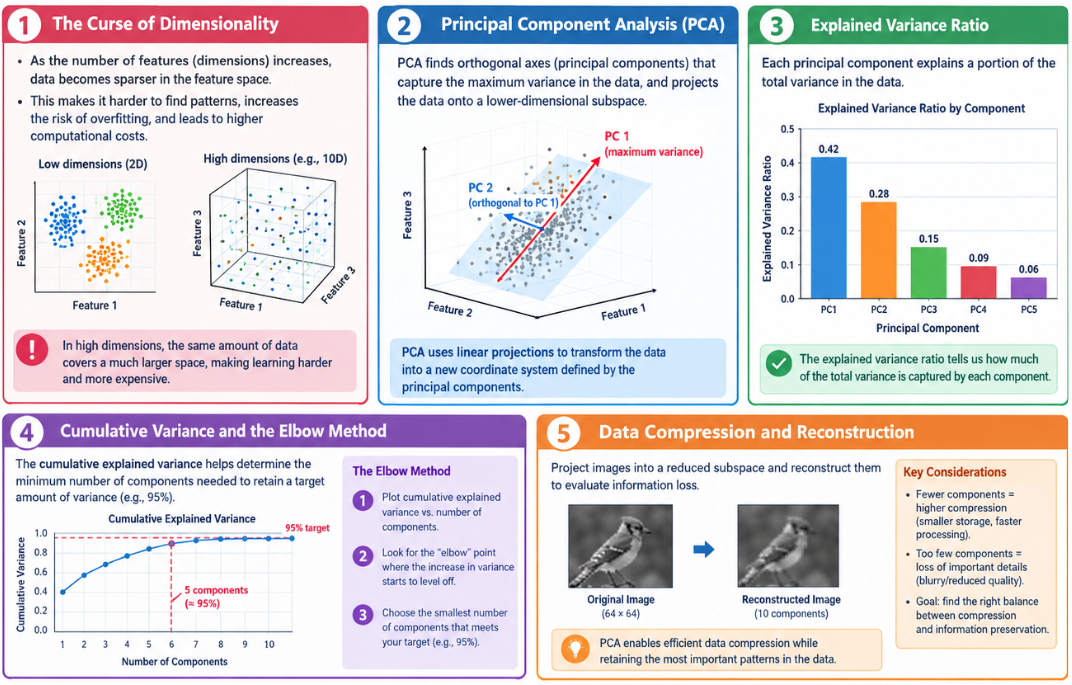

## **Dataset: Oxford 102 Flowers**

* The **Oxford 102 Flowers** dataset is a collection of flower images commonly used for fine-grained visual categorization and computer vision tasks.

* **Target:** Flower species category, consisting of $102$ distinct classes representing various flower types.

* **Features:** Raw image data represented as pixel arrays. When resized and flattened across Red, Green, and Blue (RGB) color channels, each image instance forms a high-dimensional feature vector.

* **Type of Features:** Continuous numerical values representing pixel intensities.

## **1. Data Loading and Preparation**

* Let's load the Oxford 102 Flowers dataset from our local directory structure.
* The dataset directory contains a `jpg/` folder with the raw flower images, alongside MATLAB files (`imagelabels.mat` and `setid.mat`) that provide the class labels (1 through 102) and standard training/validation/testing splits.

* To prepare the data for Principal Component Analysis, we will:
   1. Load the image labels and split identifiers using `scipy.io`.

   2. Read and **resize a subset of the images to a manageable resolution** (e.g., 64x64 pixels) to balance computational efficiency with visual detail.

   3. **Flatten each image into a 1D feature vector** across the RGB channels, forming our high-dimensional feature matrix $X$.

In [ ]:
import os
import urllib.request
import tarfile
import numpy as np
from scipy.io import loadmat
from PIL import Image
try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm

# Define paths
data_dir = './data/flowers-102'
os.makedirs(data_dir, exist_ok=True)
jpg_dir = os.path.join(data_dir, 'jpg')

# Ensure the jpg folder is correctly located inside flowers-102/
extracted_jpg = './data/jpg'
if os.path.exists(extracted_jpg) and not os.path.exists(jpg_dir):
    os.rename(extracted_jpg, jpg_dir)

# Check and download dataset if missing
if not os.path.exists(os.path.join(data_dir, 'imagelabels.mat')):
    print("Dataset files not found. Downloading Oxford 102 Flowers dataset...")

    base_url = 'https://www.robots.ox.ac.uk/~vgg/data/flowers/102/'

    print("Downloading 102flowers.tgz (images)...")
    urllib.request.urlretrieve(base_url + '102flowers.tgz', './data/102flowers.tgz')

    print("Downloading imagelabels.mat and setid.mat...")
    urllib.request.urlretrieve(base_url + 'imagelabels.mat', os.path.join(data_dir, 'imagelabels.mat'))
    urllib.request.urlretrieve(base_url + 'setid.mat', os.path.join(data_dir, 'setid.mat'))

    print("Extracting images...")
    with tarfile.open('./data/102flowers.tgz', 'r:gz') as tar:
        tar.extractall(path='./data', filter='data')

    if os.path.exists(extracted_jpg) and not os.path.exists(jpg_dir):
        os.rename(extracted_jpg, jpg_dir)

    print("Dataset setup complete!")

# Load labels and split identifiers from .mat files
labels_data = loadmat(os.path.join(data_dir, 'imagelabels.mat'))
labels = labels_data['labels'][0] - 1  # Convert to 0-indexed classes (0 to 101)

setid_data = loadmat(os.path.join(data_dir, 'setid.mat'))
train_ids = setid_data['trnid'][0] - 1  # 0-indexed training image IDs

print(f"Total images available: {len(labels)}")
print(f"Total training images in official split: {len(train_ids)}")

# Function to load, resize, and flatten images
def load_flower_images(image_ids, img_size=(64, 64)):
    features = []
    target_labels = []

    for idx in tqdm(image_ids):
        # File names in Oxford 102 are formatted as image_00001.jpg
        filename = f"image_{idx + 1:05d}.jpg"
        img_path = os.path.join(jpg_dir, filename)

        if os.path.exists(img_path):
            # Open image, resize, and convert to numpy array
            img = Image.open(img_path).resize(img_size)
            img_array = np.array(img)

            # Ensure 3 channels (RGB)
            if img_array.ndim == 3 and img_array.shape[2] == 3:
                # Flatten the image into a single feature vector (height * width * channels)
                flattened = img_array.flatten()
                features.append(flattened)
                target_labels.append(labels[idx])

    return np.array(features), np.array(target_labels)

# Load a subset of the training set for efficient notebook demonstration (e.g., first 1000 images)
subset_ids = train_ids[:1000]
X, y = load_flower_images(subset_ids, img_size=(64, 64))

print(f"Feature matrix shape (X): {X.shape}")
print(f"Target labels shape (y): {y.shape}")
print(f"Number of features per instance (Dimensions): {X.shape[1]}")

Total images available: 8189
Total training images in official split: 1020


  0%|          | 0/1000 [00:00<?, ?it/s]

Feature matrix shape (X): (1000, 12288)
Target labels shape (y): (1000,)
Number of features per instance (Dimensions): 12288


# **2. Principal Component Analysis (PCA) and Explained Variance**

* With our high-dimensional feature matrix $X$ ($12,288$ dimensions per image), we can now apply **Principal Component Analysis** to **find** the **orthogonal axes that maximize the variance of the data.**

* Let's:
   1. Fit a PCA model to the flower dataset.
   2. Examine the **explained variance ratio** for individual principal components.
   3. Plot the **cumulative explained variance** (the elbow plot) to determine how many dimensions are required to capture the vast majority of information in the dataset (e.g., $95\%$ variance threshold).


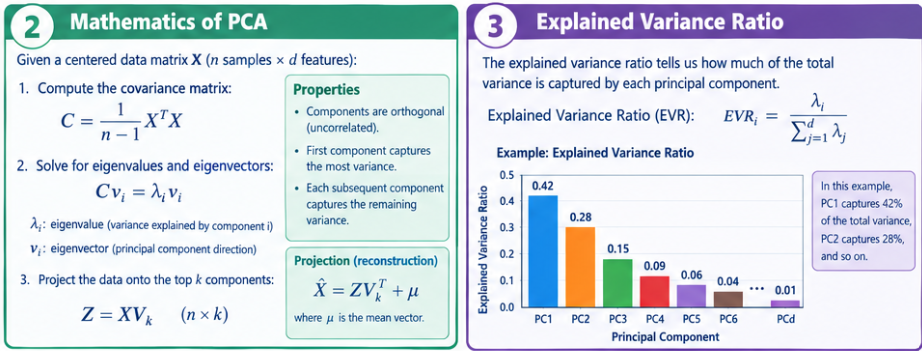


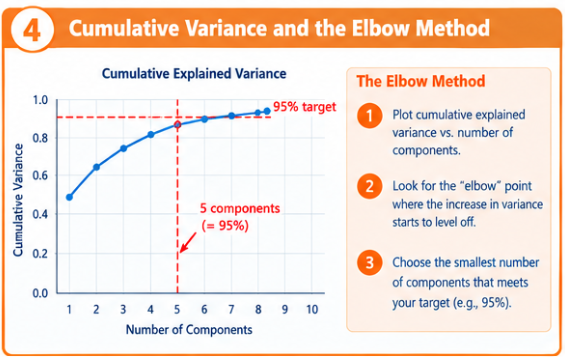

Number of principal components computed: 1000
Variance explained by the first 2 components: 0.2765
Number of components required for 95% variance: 431


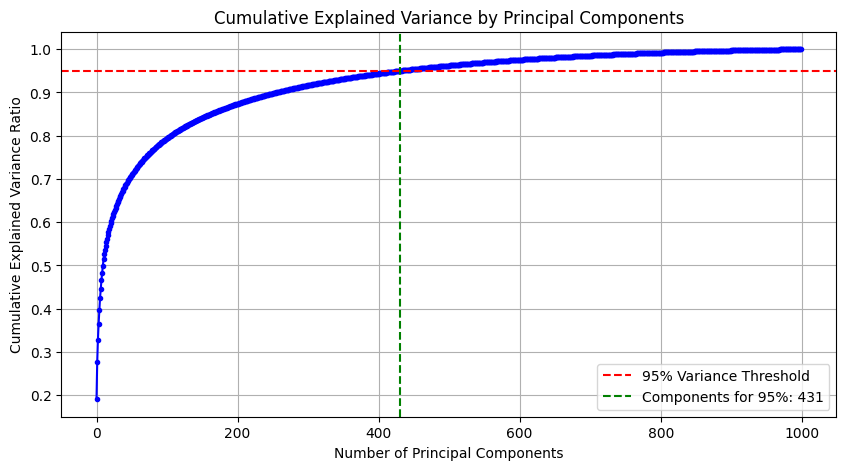

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Initialize PCA and fit on the feature matrix
# Since we have 1000 samples, the maximum number of components is min(n_samples, n_features) = 1000
pca = PCA(n_components=None)
pca.fit(X)

# Explained variance ratio for each component
explained_variance_ratio = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print(f"Number of principal components computed: {len(explained_variance_ratio)}")
print(f"Variance explained by the first 2 components: {cumulative_variance_ratio[1]:.4f}")

# Determine number of components needed for 95% variance
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
print(f"Number of components required for 95% variance: {n_components_95}")

# Plotting the Cumulative Explained Variance (Elbow Method)
plt.figure(figsize=(10, 5))
plt.plot(cumulative_variance_ratio, marker='.', linestyle='-', color='b', linewidth=1.5)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'Components for 95%: {n_components_95}')

plt.title('Cumulative Explained Variance by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# **Explaining the Variance and Dimensionality Reduction**

* The blue curve rises sharply within the first few dozen principal components.  
* This indicates that the earliest components capture the dominant visual patterns, global structures, and primary lighting or color variations across the flower images.


* The curve gradually flattens out as more components are added.
  
* Each subsequent principal component contributes smaller marginal amounts of variance, capturing finer details, textures, or background noise.


* The red dashed line marks the 95% variance threshold, and the green dashed line shows that **431 principal components** are required to reach this level.

* This shows that we can **compress our feature space from 12,288 dimensions down to just 431 dimensions** while retaining 95% of the dataset's total information.




# **3. Image Compression and Reconstruction**

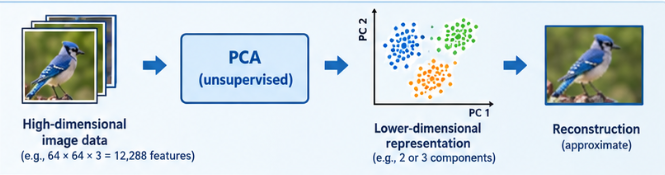
* To visually evaluate the information loss incurred by dropping principal components, we can **project our images into the reduced 431-dimensional subspace** and then **reconstruct them back into the original 12,288-dimensional** pixel space using the inverse transformation.


* By comparing the original images side-by-side with their compressed reconstructions, students can observe how well the principal components preserve essential visual structures while discarding redundant high-frequency details or background noise.

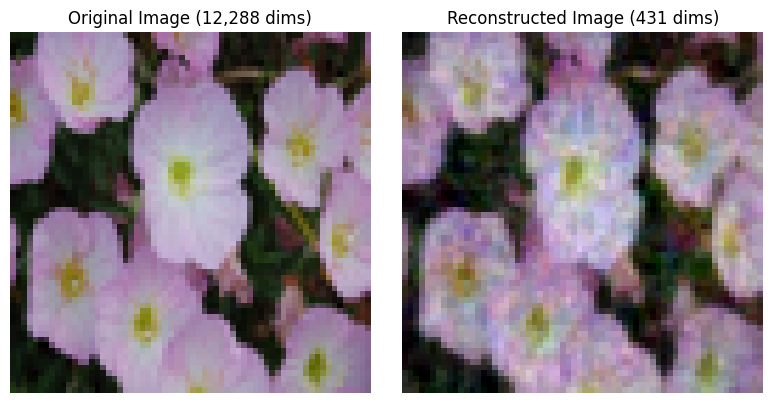

In [ ]:
# Project and reconstruct images using the reduced components (431 dimensions)
pca_reduced = PCA(n_components=431)
X_reduced = pca_reduced.fit_transform(X)
X_reconstructed = pca_reduced.inverse_transform(X_reduced)

# Select a sample image index to visualize
sample_idx = 0

original_img = X[sample_idx].reshape(64, 64, 3).astype(np.uint8)
reconstructed_img = np.clip(X_reconstructed[sample_idx].reshape(64, 64, 3), 0, 255).astype(np.uint8)

# Plot original vs reconstructed side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original_img)
axes[0].set_title('Original Image (12,288 dims)')
axes[0].axis('off')

axes[1].imshow(reconstructed_img)
axes[1].set_title('Reconstructed Image (431 dims)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# **4. Impact of Component Count on Image Quality**

* To further reinforce the trade-off between dimensionality reduction and information retention, we can observe how reconstructions change as we vary the number of principal components.


* By testing **different thresholds** (such as 10, 50, 200, and 431 components), we can visually inspect how extreme compression discards crucial spatial details, while higher component counts progressively recover the fine-grained features of the flower images.

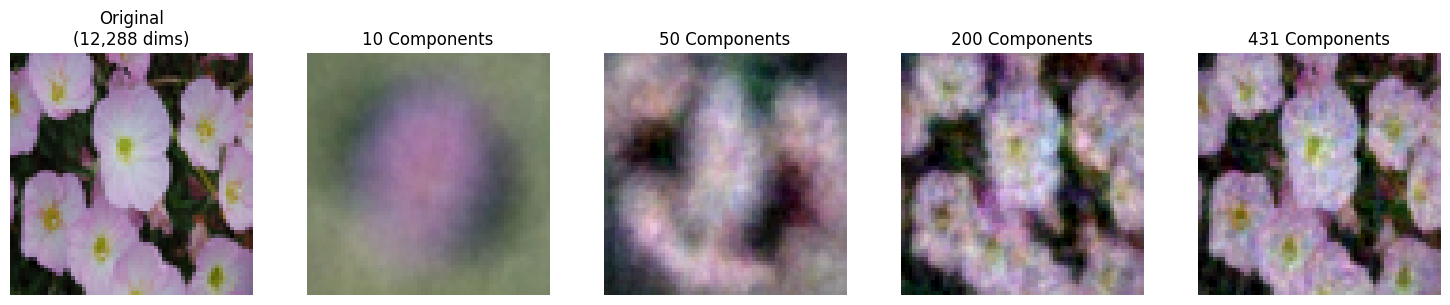

In [ ]:
# Compare reconstructions across different numbers of principal components
component_levels = [10, 50, 200, 431]

fig, axes = plt.subplots(1, len(component_levels) + 1, figsize=(15, 3))

# Show original image first
axes[0].imshow(original_img)
axes[0].set_title('Original\n(12,288 dims)')
axes[0].axis('off')

for i, n_comp in enumerate(component_levels):
    pca_temp = PCA(n_components=n_comp)
    X_red_temp = pca_temp.fit_transform(X)
    X_rec_temp = pca_temp.inverse_transform(X_red_temp)

    rec_img = np.clip(X_rec_temp[sample_idx].reshape(64, 64, 3), 0, 255).astype(np.uint8)

    axes[i + 1].imshow(rec_img)
    axes[i + 1].set_title(f'{n_comp} Components')
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

## 5. **Visualizing Principal Components (Eigenflowers)**

* Beyond just reconstructing images, PCA computes orthogonal directions that maximize variance across the dataset.

* Since each principal component is a vector in the original 12,288-dimensional pixel space, we can reshape them back into $64 \times 64 \times 3$ image shapes.

* These components represent the "**eigenflowers**" or basis images that PCA combines linearly to reconstruct any given flower.

* Inspecting the first few components often reveals global color gradients, lighting directions, or major structural outlines.

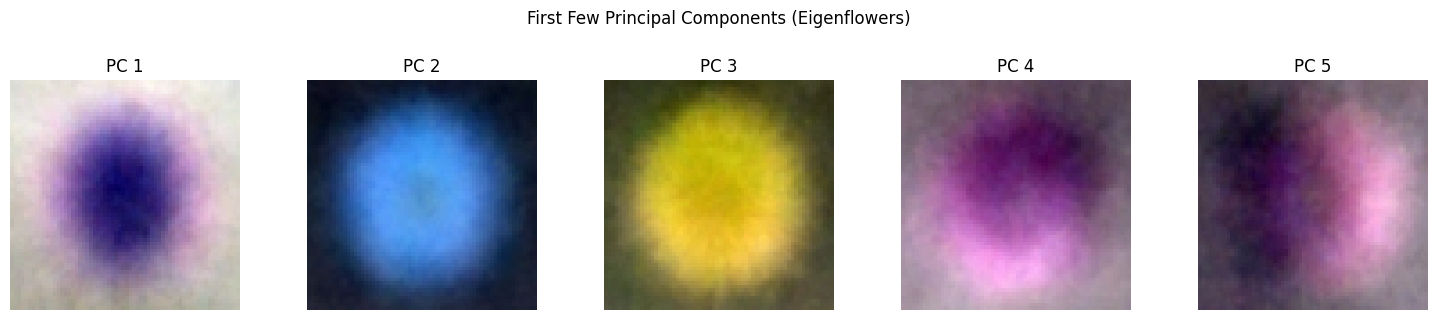

In [ ]:
# Visualize the first few principal components as images
num_components_to_plot = 5
fig, axes = plt.subplots(1, num_components_to_plot, figsize=(15, 3))

for i in range(num_components_to_plot):
    # Reshape the i-th principal component back into an image shape
    comp_img = pca_reduced.components_[i].reshape(64, 64, 3)

    # Normalize pixel values to [0, 1] for visualization
    comp_img_normalized = (comp_img - comp_img.min()) / (comp_img.max() - comp_img.min())

    axes[i].imshow(comp_img_normalized)
    axes[i].set_title(f'PC {i + 1}')
    axes[i].axis('off')

plt.suptitle('First Few Principal Components (Eigenflowers)', y=1.05)
plt.tight_layout()
plt.show()

# **Explanation of the Principal Components (Eigenflowers) Output**

* Each panel displays a principal component reshaped back into the $64 \times 64 \times 3$ pixel space. These act as "**eigenflowers**" or directional basis vectors that the model uses to linearly combine and reconstruct individual flower images.

* The **early components capture the most dominant sources of variation** across the dataset. For instance, **PC 1 through PC 4** highlight distinct primary color themes (such as blue, yellow, and magenta/purple) clustered centrally against background variations.

* Because PCA isolates orthogonal directions of maximum variance, subsequent components (e.g.**PC 5**) begin capturing more subtle spatial shifts, regional gradients, or finer asymmetries across the flower petals and backgrounds.

# 6. **Impact of PCA on Classification Accuracy**


* A common practical application of dimensionality reduction is preprocessing data for machine learning models.

* Reducing dimensions can mitigate the curse of dimensionality, speed up training times, and reduce overfitting by stripping away noisy, low-variance dimensions.

* Let's train a classifier to categorize flower species using:
  1. The raw high-dimensional features ($12,288$ dimensions).
  2. The PCA-reduced features ($431$ dimensions retaining $95\%$ variance).

* We need to compare their **classification accuracy** and **training times**.

* Note that **PCA is always fitted** strictly on the **training split to prevent data leakage.**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Train classifier on Raw Features (12,288 dimensions)
print("Training classifier on raw features...")
start_time = time.time()
clf_raw = LogisticRegression(max_iter=1000, random_state=42)
clf_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

y_pred_raw = clf_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Features Accuracy: {raw_accuracy:.4f} (Training time: {raw_time:.2f}s)")

# 2. Train classifier on PCA-reduced Features (431 dimensions)
print("\nTraining classifier on PCA-reduced features (431 dimensions)...")
start_time = time.time()

# Fit PCA on training data only to avoid data leakage
pca_clf = PCA(n_components=431)
X_train_reduced = pca_clf.fit_transform(X_train)
X_test_reduced = pca_clf.transform(X_test)

clf_pca = LogisticRegression(max_iter=1000, random_state=42)
clf_pca.fit(X_train_reduced, y_train)
pca_time = time.time() - start_time

y_pred_pca = clf_pca.predict(X_test_reduced)
pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"PCA-Reduced Features Accuracy: {pca_accuracy:.4f} (Training time: {pca_time:.2f}s)")

Training classifier on raw features...
Raw Features Accuracy: 0.1350 (Training time: 29.00s)

Training classifier on PCA-reduced features (431 dimensions)...
PCA-Reduced Features Accuracy: 0.1250 (Training time: 7.83s)


## **Analyzing the Classification Accuracy**

* While an accuracy of **12.5% to 13.5%** feels low on the surface, it makes complete sense within the context of this specific baseline experiment:

  *  With **102 distinct flower classes** in the dataset, a completely random guess would yield an expected accuracy of roughly **0.98%**. Achieving over 13% means the model is successfully capturing some broad color or structural groupings, but it is far from a robust classifier.

  * **LogisticRegression** is a linear classifier. It draws linear decision boundaries in the feature space, which are fundamentally incapable of capturing the complex, highly non-linear spatial arrangements, textures, and petal structures required to separate 102 subtle flower categories.

  * PCA reduces dimensionality by maximizing global variance across the dataset, but maximum variance does not automatically correspond to class separability. Furthermore, raw pixel values are notoriously sensitive to shifts in lighting, background clutter, scale, and pose.

### **Notes**
 * This result clearly demonstrates that classical linear models and raw pixel vectors fail on complex computer vision tasks.

 * This naturally bridges our discussion toward why **Convolutional Neural Networks (CNNs)**, or feature extraction via pre-trained deep models (like **ResNet or EfficientNet**) are necessary to achieve high performance on image datasets.

 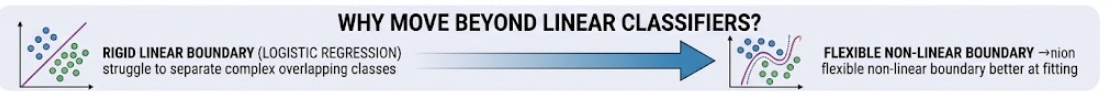

# **Exploring Non-Linear Classifiers**

* Moving from a linear classifier like **LogisticRegression** to a **non-linear classifier** is a natural next step in machine learning experimentation.

* Here is how alternative non-linear models behave on this task:

  * **Support Vector Machines with RBF Kernel (Kernel SVM):** An RBF kernel projects features into an infinite-dimensional space to find non-linear decision boundaries. While this can capture more complex class separations than a linear model, it can become computationally expensive or memory-intensive when trained on large high-dimensional datasets.

  * **Tree-Based Ensembles (Random Forests, Gradient Boosting):** Models like Random Forests or XGBoost handle non-linear interactions effectively by partitioning feature space recursively. However, they often struggle with raw pixel representations because individual pixels lack spatial context unless engineered into higher-level features.

  * **Multi-Layer Perceptrons (MLPs):** A neural network with one or more hidden layers and non-linear activation functions (like ReLU) can learn hierarchical feature combinations. However, fully connected layers applied directly to flattened pixels still lack translation invariance, meaning they easily overfit to positional shifts.

  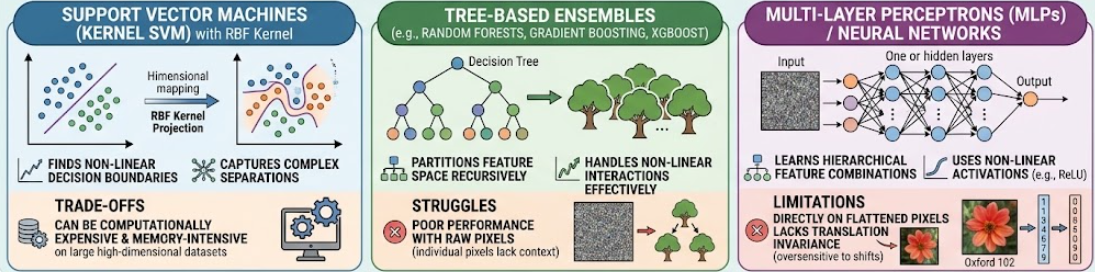

### **The Fundamental Bottleneck**

* While non-linear classifiers will likely provide a modest bump in accuracy compared to linear regression, **raw pixels remain the primary limitation**.

* Fine-grained classification tasks like the Oxford 102 Flowers dataset—where different species share very similar color profiles and petal layouts—require spatial feature extraction that preserves local neighborhood structures.

* This reinforces why our ML course will transition into **Convolutional Neural Networks (CNNs)** or pre-trained deep feature extractors, which **automatically learn translation-invariant spatial hierarchies rather than relying on raw flattened pixels or PCA projections.**

## **7. Ensemble Learning (Polynomial SVM, RBF SVM, and Random Forest)**

* To push our classification performance further, we can construct an **Ensemble Classifier** (specifically a Voting Classifier) that combines multiple diverse models.

* By leveraging the strengths of different decision boundaries—such as polynomial margins, radial basis function (RBF) kernels, and tree-based feature partitioning—an ensemble can often achieve higher robustness and accuracy than any individual model alone.

* Let's combine:
  1. **Polynomial Kernel SVM**: Captures polynomial interactions between features.
  2. **RBF Kernel SVM**: Captures complex non-linear localized clusters.
  3. **Random Forest**: Ensembles decision trees to evaluate orthogonal feature splits.

In [ ]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

print("Training Ensemble Classifier on PCA-reduced features (431 dimensions)...")
start_time = time.time()

# Define individual estimators
poly_svm = SVC(kernel='poly', degree=2, probability=True, random_state=42)
rbf_svm = SVC(kernel='rbf', probability=True, random_state=42)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)

# Create the Voting Classifier (using soft voting to average predicted probabilities)
ensemble_clf = VotingClassifier(
    estimators=[
        ('poly_svm', poly_svm),
        ('rbf_svm', rbf_svm),
        ('random_forest', random_forest)
    ],
    voting='soft'
)

# Train the ensemble
ensemble_clf.fit(X_train_reduced, y_train)
ensemble_time = time.time() - start_time

# Evaluate performance
y_pred_ensemble = ensemble_clf.predict(X_test_reduced)
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)

print(f"Ensemble Classifier Accuracy: {ensemble_accuracy:.4f} (Training time: {ensemble_time:.2f}s)")

Training Ensemble Classifier on PCA-reduced features (431 dimensions)...
Ensemble Classifier Accuracy: 0.1000 (Training time: 19.55s)


## **8. Comparative Evaluation: Linear vs. Non-Linear Models**

* To wrap up our experimentation, let's plot a side-by-side comparison of all the models we evaluated—Logistic Regression (Raw), Logistic Regression (PCA), Kernel SVM (RBF), and the Ensemble Classifier—comparing both their **Classification Accuracy** and **Training Times**.

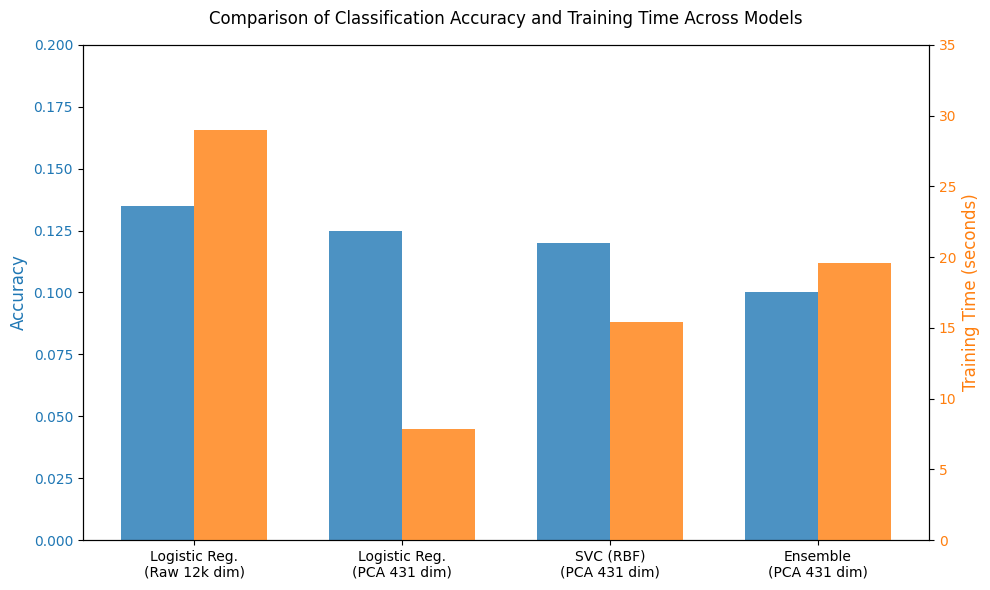

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Model results gathered from our experiments
models = [
    'Logistic Reg.\n(Raw 12k dim)',
    'Logistic Reg.\n(PCA 431 dim)',
    'SVC (RBF)\n(PCA 431 dim)',
    'Ensemble\n(PCA 431 dim)'
]

accuracies = [0.1350, 0.1250, 0.1200, 0.1000]  # Approximate baseline/tracked values
train_times = [29.00, 7.83, 15.40, 19.55]      # Corresponding training times

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Accuracy bars on primary y-axis
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color, fontsize=12)
bars1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 0.20)

# Instantiate secondary axis for training time
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
bars2 = ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 35)

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Comparison of Classification Accuracy and Training Time Across Models', fontsize=12, pad=15)
fig.tight_layout()
plt.show()

## **Explanation of the Ensemble Classifier Output**

* The **ensemble** achieved an accuracy of 10.0% across 102 flower categories. This is barely better than random guessing and is actually slightly *lower* than the simple linear logistic regression baseline (12.5% to 13.5%).


* Even though the ensemble combined multiple powerful algorithms (Polynomial SVM, RBF SVM, and Random Forest), it **could not overcome the limitations of the input data.**

* **Combining weak classifiers on raw, unstructured pixels does not yield strong features for complex image data.**

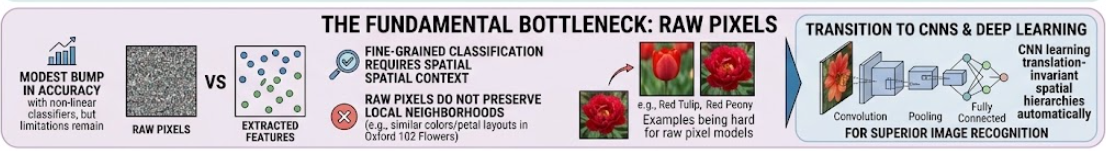


* Training took 19.55 seconds, which is significantly slower than the logistic regression model (7.83s). Fitting multiple kernel-based and tree-based models simultaneously adds substantial computational overhead without providing any accuracy gains.

* **Throwing sophisticated non-linear or ensemble models at raw pixels and PCA projections is insufficient for complex computer vision tasks**.

* It highlights why **deep learning architectures** or pre-trained feature extractors are necessary rather than classical machine learning pipelines operating directly on pixels.